In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from IPython.display import display

In [2]:
import gc
import polars as pl

from analysis_data import CACHE_DIR, load_analysis_frame

target_column = "status_penanganan"

# Hemat RAM: jangan simpan full analysis_frame di memori.
# Pastikan cache parquet ada, lalu baca HANYA kolom yang dibutuhkan.
train_path = CACHE_DIR / "analysis_frame_train.parquet"
test_path = CACHE_DIR / "analysis_frame_test.parquet"

for split, path in [("train", train_path), ("test", test_path)]:
    if not path.exists():
        _tmp = load_analysis_frame(split)
        del _tmp
        gc.collect()

train_columns = pl.scan_parquet(train_path).collect_schema().names()
test_columns = pl.scan_parquet(test_path).collect_schema().names()

if target_column not in train_columns:
    raise ValueError(f"Kolom {target_column} tidak ditemukan.")

entity_candidates = [
    "customer_id",
    "courier_id",
    "hub_id"
]

entity_columns = [
    col for col in entity_candidates
    if col in train_columns and col in test_columns
]

if not entity_columns:
    raise ValueError("Tidak ditemukan kolom customer_id, courier_id, atau hub_id.")

safe_numeric_candidates = [
    "declared_value",
    "distance_km",
    "weight_kg",
    "qty_items",
    "volume_l",
    "is_cod",
    "flag_alamat_baru",
    "ship_month",
    "ship_hour",
    "ship_dow"
]

numeric_columns = [
    col for col in safe_numeric_candidates
    if col in train_columns and col in test_columns
]

selected_train_columns = list(dict.fromkeys(
    entity_columns + numeric_columns + [target_column]
))

selected_test_columns = list(dict.fromkeys(
    entity_columns + numeric_columns
))

train_pl = pl.read_parquet(train_path, columns=selected_train_columns)
test_pl = pl.read_parquet(test_path, columns=selected_test_columns)

# ID entitas -> Enum dengan kategori gabungan train+test,
# sehingga di pandas menjadi Categorical (kode int32, bukan string per baris)
# dan kode kategori train/test konsisten.
for entity in entity_columns:
    categories = (
        pl.concat([
            train_pl[entity].cast(pl.Utf8),
            test_pl[entity].cast(pl.Utf8)
        ])
        .drop_nulls()
        .unique()
        .sort()
    )
    entity_enum = pl.Enum(categories)
    train_pl = train_pl.with_columns(pl.col(entity).cast(pl.Utf8).cast(entity_enum))
    test_pl = test_pl.with_columns(pl.col(entity).cast(pl.Utf8).cast(entity_enum))

numeric_casts = [pl.col(c).cast(pl.Float32, strict=False) for c in numeric_columns]
train_pl = train_pl.with_columns(numeric_casts)
test_pl = test_pl.with_columns(numeric_casts)

train_entity = train_pl.to_pandas().reset_index(drop=True)
test_entity = test_pl.to_pandas().reset_index(drop=True)

del train_pl, test_pl
gc.collect()

train_entity[target_column] = train_entity[target_column].astype("category")

print(f"Jumlah baris train: {len(train_entity):,}")
print(f"Jumlah baris test: {len(test_entity):,}")
print(f"Entitas yang dianalisis: {entity_columns}")
print(f"Fitur numerik: {numeric_columns}")
print(f"Jumlah kelas target: {train_entity[target_column].nunique()}")
print(f"Memori train_entity: {train_entity.memory_usage(deep=True).sum() / 1e6:,.1f} MB")

Jumlah baris train: 1,243,617
Jumlah baris test: 362,245
Entitas yang dianalisis: ['customer_id', 'courier_id', 'hub_id']
Fitur numerik: ['declared_value', 'distance_km', 'weight_kg', 'qty_items', 'volume_l', 'is_cod', 'flag_alamat_baru', 'ship_month', 'ship_hour', 'ship_dow']
Jumlah kelas target: 7
Memori train_entity: 72.2 MB


In [3]:
entity_completeness = []

for entity in entity_columns:
    entity_completeness.append({
        "entity": entity,
        "missing_train": train_entity[entity].isna().sum(),
        "missing_train_pct": train_entity[entity].isna().mean() * 100,
        "missing_test": test_entity[entity].isna().sum(),
        "missing_test_pct": test_entity[entity].isna().mean() * 100,
        "unique_train": train_entity[entity].nunique(),
        "unique_test": test_entity[entity].nunique(),
        "unique_combined": pd.concat(
            [train_entity[entity], test_entity[entity]],
            ignore_index=True
        ).nunique()
    })

entity_completeness = pd.DataFrame(entity_completeness)

display(entity_completeness)

,entity,missing_train,missing_train_pct,missing_test,missing_test_pct,unique_train,unique_test,unique_combined
0,customer_id,0,0.0,0,0.0,508086,268812,538977
1,courier_id,0,0.0,0,0.0,23806,23806,23806
2,hub_id,0,0.0,0,0.0,654,654,654


In [4]:
entity_distribution = []
entity_counts_cache = {}

for entity in entity_columns:
    counts = train_entity.groupby(entity, observed=True, dropna=False).size()
    entity_counts_cache[entity] = counts

    entity_distribution.append({
        "entity": entity,
        "total_shipments": len(train_entity),
        "unique_entities": counts.size,
        "mean_shipments": counts.mean(),
        "median_shipments": counts.median(),
        "std_shipments": counts.std(),
        "min_shipments": counts.min(),
        "max_shipments": counts.max(),
        "p90_shipments": counts.quantile(0.90),
        "p95_shipments": counts.quantile(0.95),
        "p99_shipments": counts.quantile(0.99)
    })

entity_distribution = pd.DataFrame(entity_distribution)

display(entity_distribution)

,entity,total_shipments,unique_entities,mean_shipments,median_shipments,std_shipments,min_shipments,max_shipments,p90_shipments,p95_shipments,p99_shipments
0,customer_id,1243617,508086,2.447651,2.0,1.328912,1,13,4.0,5.0,6.00
1,courier_id,1243617,23806,52.239645,52.0,7.226011,27,85,62.0,65.0,70.00
2,hub_id,1243617,654,1901.555046,1900.5,336.718930,961,3068,2324.3,2473.7,2680.47


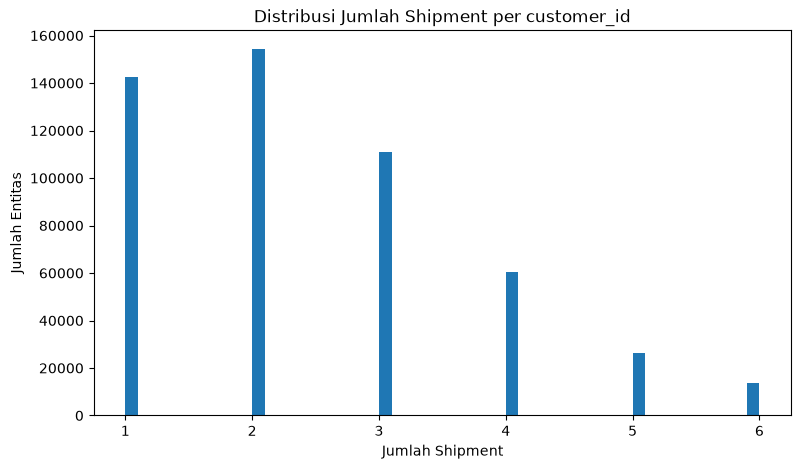

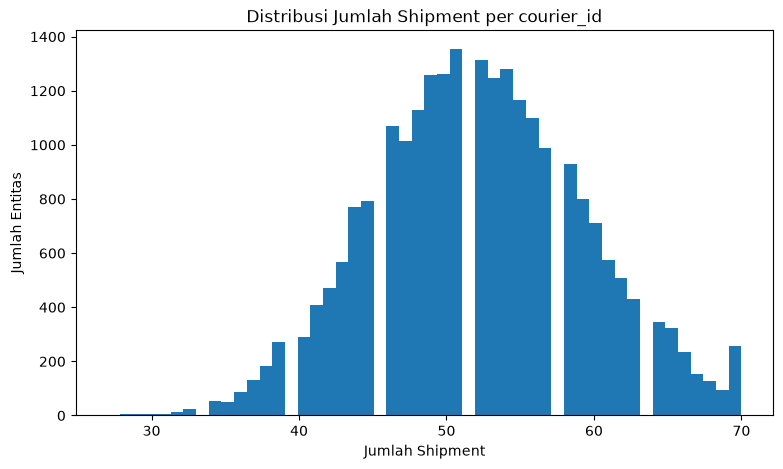

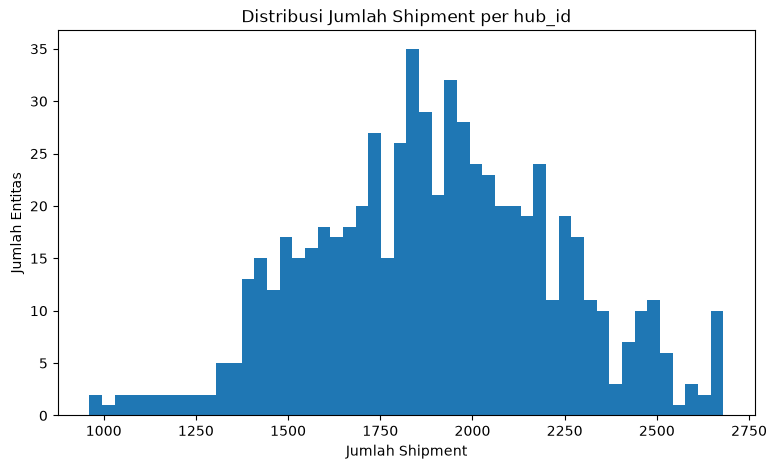

In [5]:
for entity in entity_columns:
    counts = entity_counts_cache[entity]

    plt.figure(figsize=(9, 5))
    plt.hist(
        counts.clip(upper=counts.quantile(0.99)),
        bins=50
    )
    plt.title(f"Distribusi Jumlah Shipment per {entity}")
    plt.xlabel("Jumlah Shipment")
    plt.ylabel("Jumlah Entitas")
    plt.show()
    plt.close()

In [6]:
top_entities = {}

for entity in entity_columns:
    top = (
        entity_counts_cache[entity]
        .nlargest(20)
        .rename("shipment_count")
        .reset_index()
    )
    top[entity] = top[entity].astype(str)

    top_entities[entity] = top

    print(f"\nTop 20 {entity}")
    display(top)


Top 20 customer_id


,customer_id,shipment_count
0,CUS-UYM5WXLC,13
1,CUS-U3G5SQJW,12
2,CUS-3A4KUDKF,11
3,CUS-7QA8FRM7,11
4,CUS-9SRVGT86,11
5,CUS-D74PTZV2,11
6,CUS-P5CNAAFT,11
7,CUS-QTAV4Y5Z,11
8,CUS-X3JMAYC5,11
9,CUS-XBXCXB4Q,11



Top 20 courier_id


,courier_id,shipment_count
0,CRV-49YVD7JA,85
1,CRV-57XMF9C7,83
2,CRV-GQQCY5PK,82
3,CRV-6ZCFWZ8D,81
4,CRV-C7V9WNZP,80
5,CRV-JAHXELPL,80
6,CRV-X6UBUK9N,80
7,CRV-YCQUKAE3,80
8,CRV-CMBQUWV5,78
9,CRV-DNWCAPQK,78



Top 20 hub_id


,hub_id,shipment_count
0,HUB-HK38UG82,3068
1,HUB-5S4D29X4,2776
2,HUB-QU2X57V3,2762
3,HUB-UX286HC3,2748
4,HUB-76PSQJKF,2710
5,HUB-HU3X8H6F,2694
6,HUB-8DB4624Q,2681
7,HUB-LHB7CWW6,2680
8,HUB-7LCJWXDG,2658
9,HUB-FL57K5VJ,2654


In [7]:
entity_target_distributions = {}

for entity in entity_columns:
    # groupby+value_counts jauh lebih hemat RAM dibanding pd.crosstab
    distribution = (
        train_entity
        .groupby(entity, observed=True)[target_column]
        .value_counts(normalize=True)
        .unstack(fill_value=0)
        .astype("float32")
    )

    entity_target_distributions[entity] = distribution

    print(f"\nDistribusi target berdasarkan {entity}")
    display(distribution.head(20))

gc.collect()


Distribusi target berdasarkan customer_id


status_penanganan,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
customer_id,,,,,,,
CUS-2224QQD3,0.000000,0.0,1.0,0.000000,0.00,0.0,0.000000
CUS-22258A6Z,0.000000,0.0,0.0,1.000000,0.00,0.0,0.000000
CUS-2225EDLA,0.000000,0.0,0.0,1.000000,0.00,0.0,0.000000
CUS-22262N9G,0.000000,0.0,0.0,0.500000,0.50,0.0,0.000000
CUS-222BTQHD,0.000000,0.0,1.0,0.000000,0.00,0.0,0.000000
CUS-222BYXWM,0.000000,0.0,0.0,1.000000,0.00,0.0,0.000000
CUS-222CXTUW,0.000000,0.0,0.0,0.500000,0.00,0.0,0.500000
CUS-222D85T9,0.000000,0.0,0.0,1.000000,0.00,0.0,0.000000
CUS-222E24SJ,0.500000,0.0,0.0,0.500000,0.00,0.0,0.000000



Distribusi target berdasarkan courier_id


status_penanganan,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
courier_id,,,,,,,
CRV-225NDW23,0.000000,0.062500,0.229167,0.625000,0.041667,0.000000,0.041667
CRV-226NMCY5,0.087719,0.000000,0.210526,0.543860,0.087719,0.017544,0.052632
CRV-2292BCGD,0.086957,0.065217,0.347826,0.130435,0.086957,0.130435,0.152174
CRV-22C75NBA,0.122449,0.000000,0.265306,0.510204,0.040816,0.020408,0.040816
CRV-22DMTFCT,0.046512,0.000000,0.279070,0.325581,0.046512,0.000000,0.302326
CRV-22FBDFF4,0.508772,0.017544,0.035088,0.017544,0.105263,0.298246,0.017544
CRV-22FNTWKE,0.100000,0.020000,0.200000,0.560000,0.080000,0.020000,0.020000
CRV-22FVUF92,0.017241,0.000000,0.155172,0.431034,0.000000,0.000000,0.396552
CRV-22H2XMBR,0.170213,0.063830,0.234043,0.170213,0.021277,0.042553,0.297872



Distribusi target berdasarkan hub_id


status_penanganan,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
hub_id,,,,,,,
HUB-22D4B2F7,0.075750,0.003156,0.192530,0.463966,0.068911,0.036297,0.159390
HUB-22X96KLN,0.106024,0.008193,0.250120,0.403855,0.078554,0.057349,0.095904
HUB-23EYRTRX,0.107077,0.008000,0.188923,0.328000,0.062769,0.051077,0.254154
HUB-24UEL3ZX,0.107570,0.005755,0.210270,0.416999,0.073484,0.045153,0.140770
HUB-257FX389,0.126622,0.005189,0.206539,0.418786,0.075246,0.052932,0.114686
HUB-25M4FHMM,0.127160,0.022115,0.262612,0.393227,0.085003,0.056669,0.053214
HUB-25YH85QF,0.139706,0.048077,0.260747,0.304864,0.087104,0.061086,0.098416
HUB-298M6Y5Q,0.073256,0.005233,0.196512,0.550581,0.056977,0.037791,0.079651
HUB-2AM4LL6N,0.131092,0.147173,0.282651,0.268519,0.087719,0.067739,0.015107


16024

In [8]:
top_entity_target_rates = {}

for entity in entity_columns:
    selected_entities = entity_counts_cache[entity].nlargest(20).index

    distribution = entity_target_distributions[entity].loc[selected_entities].copy()
    distribution.index = distribution.index.astype(str)

    top_entity_target_rates[entity] = distribution

    print(f"\nTarget rate top 20 {entity}")
    display(distribution)


Target rate top 20 customer_id


status_penanganan,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
customer_id,,,,,,,
CUS-UYM5WXLC,0.230769,0.000000,0.692308,0.076923,0.000000,0.000000,0.000000
CUS-U3G5SQJW,0.000000,0.000000,0.000000,0.750000,0.000000,0.166667,0.083333
CUS-3A4KUDKF,0.000000,0.000000,0.909091,0.090909,0.000000,0.000000,0.000000
CUS-7QA8FRM7,0.181818,0.090909,0.272727,0.090909,0.090909,0.090909,0.181818
CUS-9SRVGT86,0.363636,0.000000,0.000000,0.090909,0.000000,0.000000,0.545455
CUS-D74PTZV2,0.090909,0.000000,0.636364,0.272727,0.000000,0.000000,0.000000
CUS-P5CNAAFT,0.181818,0.181818,0.000000,0.454545,0.000000,0.000000,0.181818
CUS-QTAV4Y5Z,0.000000,0.000000,0.000000,0.545455,0.363636,0.000000,0.090909
CUS-X3JMAYC5,0.454545,0.000000,0.000000,0.363636,0.000000,0.000000,0.181818



Target rate top 20 courier_id


status_penanganan,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
courier_id,,,,,,,
CRV-49YVD7JA,0.000000,0.000000,0.176471,0.552941,0.047059,0.011765,0.211765
CRV-57XMF9C7,0.072289,0.060241,0.361446,0.228916,0.084337,0.048193,0.144578
CRV-GQQCY5PK,0.036585,0.024390,0.256098,0.609756,0.048780,0.012195,0.012195
CRV-6ZCFWZ8D,0.012346,0.000000,0.209877,0.691358,0.061728,0.000000,0.024691
CRV-C7V9WNZP,0.125000,0.000000,0.175000,0.400000,0.050000,0.025000,0.225000
CRV-JAHXELPL,0.137500,0.050000,0.300000,0.275000,0.137500,0.075000,0.025000
CRV-X6UBUK9N,0.237500,0.000000,0.200000,0.250000,0.100000,0.175000,0.037500
CRV-YCQUKAE3,0.200000,0.112500,0.300000,0.275000,0.050000,0.062500,0.000000
CRV-CMBQUWV5,0.038462,0.000000,0.115385,0.833333,0.012821,0.000000,0.000000



Target rate top 20 hub_id


status_penanganan,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
hub_id,,,,,,,
HUB-HK38UG82,0.113103,0.007823,0.210887,0.500000,0.071382,0.058018,0.038787
HUB-5S4D29X4,0.096902,0.012968,0.195605,0.222622,0.072767,0.046110,0.353026
HUB-QU2X57V3,0.119479,0.041274,0.237871,0.436278,0.077118,0.070963,0.017017
HUB-UX286HC3,0.089156,0.010917,0.211790,0.580786,0.060044,0.039301,0.008006
HUB-76PSQJKF,0.077122,0.020664,0.266052,0.319188,0.098893,0.046125,0.171956
HUB-HU3X8H6F,0.123237,0.008909,0.214180,0.516704,0.058649,0.061990,0.016333
HUB-8DB4624Q,0.096233,0.014174,0.220440,0.509511,0.082805,0.044759,0.032078
HUB-LHB7CWW6,0.107090,0.134328,0.280970,0.219776,0.095522,0.054478,0.107836
HUB-7LCJWXDG,0.103837,0.002257,0.175320,0.594432,0.050038,0.059819,0.014296


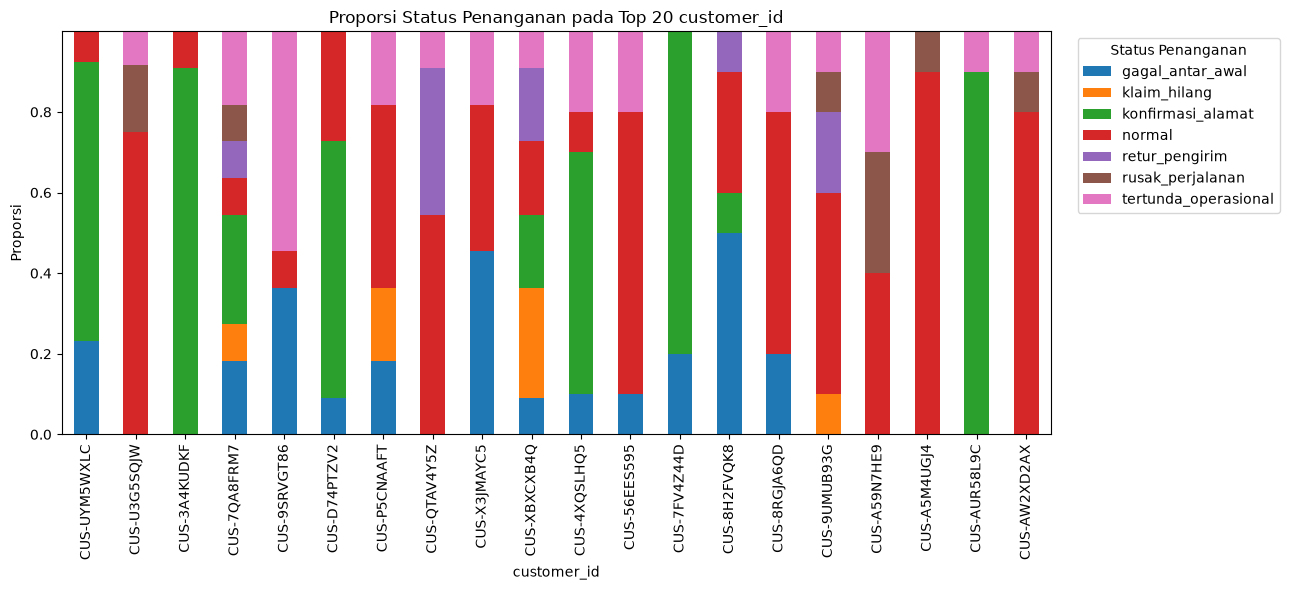

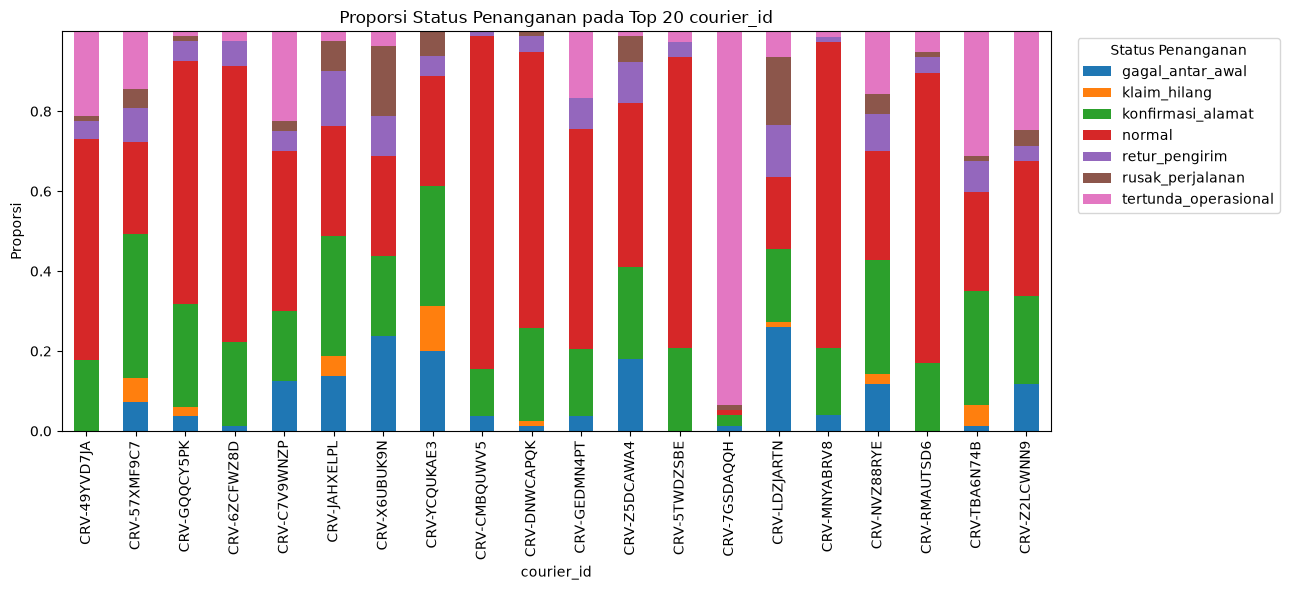

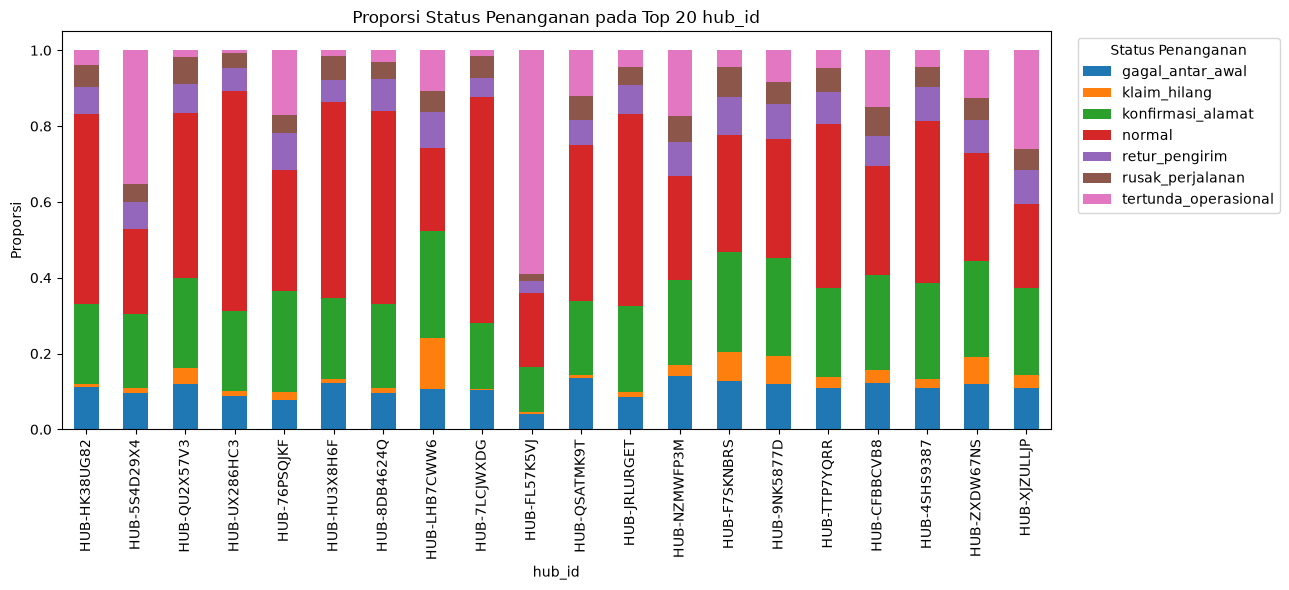

In [9]:
for entity in entity_columns:
    distribution = top_entity_target_rates[entity]

    ax = distribution.plot(
        kind="bar",
        stacked=True,
        figsize=(13, 6),
        title=f"Proporsi Status Penanganan pada Top 20 {entity}"
    )

    ax.set_xlabel(entity)
    ax.set_ylabel("Proporsi")
    ax.legend(
        title="Status Penanganan",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()
    plt.close()

In [10]:
entity_target_variation = []

for entity in entity_columns:
    # pakai ulang hasil cell sebelumnya, tidak dihitung ulang
    entity_class_rates = entity_target_distributions[entity]

    for class_name in train_entity[target_column].dropna().unique():
        if class_name not in entity_class_rates.columns:
            continue

        rates = entity_class_rates[class_name]

        entity_target_variation.append({
            "entity": entity,
            "class": class_name,
            "mean_rate": rates.mean(),
            "median_rate": rates.median(),
            "std_rate": rates.std(),
            "min_rate": rates.min(),
            "max_rate": rates.max(),
            "p90_rate": rates.quantile(0.90),
            "p10_rate": rates.quantile(0.10)
        })

entity_target_variation = pd.DataFrame(entity_target_variation)

display(
    entity_target_variation.sort_values(
        ["entity", "std_rate"],
        ascending=[True, False]
    )
)

# distribusi penuh (500rb+ baris untuk customer) tidak dipakai lagi
del entity_target_distributions
gc.collect()

,entity,class,mean_rate,median_rate,std_rate,min_rate,max_rate,p90_rate,p10_rate
7,courier_id,normal,0.380761,0.377358,0.233902,0.000000,0.981481,0.700000,0.055556
12,courier_id,tertunda_operasional,0.149163,0.046875,0.219041,0.000000,1.000000,0.483046,0.000000
11,courier_id,gagal_antar_awal,0.100000,0.058824,0.111310,0.000000,0.688889,0.266667,0.000000
9,courier_id,konfirmasi_alamat,0.219422,0.220169,0.081543,0.000000,0.538462,0.325581,0.112903
13,courier_id,rusak_perjalanan,0.049853,0.021739,0.066291,0.000000,0.559322,0.140000,0.000000
10,courier_id,klaim_hilang,0.030268,0.016949,0.050567,0.000000,0.692308,0.086207,0.000000
8,courier_id,retur_pengirim,0.070534,0.066667,0.044061,0.000000,0.315789,0.129630,0.018182
0,customer_id,normal,0.381104,0.333333,0.399908,0.000000,1.000000,1.000000,0.000000
2,customer_id,konfirmasi_alamat,0.217088,0.000000,0.363448,0.000000,1.000000,1.000000,0.000000
5,customer_id,tertunda_operasional,0.149394,0.000000,0.274168,0.000000,1.000000,0.500000,0.000000


23013

In [11]:
entity_concentration = []

for entity in entity_columns:
    counts = entity_counts_cache[entity].sort_values(ascending=False)

    total_shipments = counts.sum()

    for top_pct in [0.01, 0.05, 0.10]:
        n_entities = max(1, int(np.ceil(len(counts) * top_pct)))
        shipment_share = counts.head(n_entities).sum() / total_shipments

        entity_concentration.append({
            "entity": entity,
            "top_entity_percentage": top_pct * 100,
            "number_of_entities": n_entities,
            "shipment_share_percentage": shipment_share * 100
        })

entity_concentration = pd.DataFrame(entity_concentration)

display(entity_concentration)

,entity,top_entity_percentage,number_of_entities,shipment_share_percentage
0,customer_id,1.0,5081,2.883364
1,customer_id,5.0,25405,11.731586
2,customer_id,10.0,50809,21.058895
3,courier_id,1.0,239,1.396813
4,courier_id,5.0,1191,6.484874
5,courier_id,10.0,2381,12.507790
6,hub_id,1.0,7,1.563102
7,hub_id,5.0,33,6.880495
8,hub_id,10.0,66,13.254644


In [12]:
def class_to_slug(class_name):
    return re.sub(r"[^a-zA-Z0-9]+", "_", str(class_name)).strip("_").lower()


def make_entity_features(
    reference_df,
    query_df,
    entity_column,
    numeric_columns,
    target_column,
    target_classes
):
    """Fitur agregat per entitas berbasis kode kategori + np.bincount.

    Hasil sama dengan versi groupby/map sebelumnya, tetapi tanpa
    konversi ke string dan tanpa copy DataFrame (hemat RAM).
    Kolom entity_column harus bertipe category dengan kategori yang
    sama antara reference_df dan query_df (diatur di cell load data).
    """
    entity_name = entity_column.replace("_id", "")
    prefix = f"ent_{entity_name}_"

    n_categories = len(reference_df[entity_column].cat.categories)
    missing_key = n_categories          # slot khusus untuk entitas missing
    n_keys = n_categories + 1

    def get_codes(df):
        codes = df[entity_column].cat.codes.to_numpy().astype(np.int64)
        codes[codes < 0] = missing_key
        return codes

    ref_codes = get_codes(reference_df)
    qry_codes = get_codes(query_df)

    counts = np.bincount(ref_codes, minlength=n_keys).astype(np.float64)
    query_seen = counts[qry_codes] > 0

    output = {}
    output[f"{prefix}entity_shipment_count"] = counts[qry_codes]

    for col in numeric_columns:
        values = pd.to_numeric(reference_df[col], errors="coerce").to_numpy(
            dtype=np.float64
        )
        valid = ~np.isnan(values)
        sums = np.bincount(ref_codes[valid], weights=values[valid], minlength=n_keys)
        n_valid = np.bincount(ref_codes[valid], minlength=n_keys)

        with np.errstate(invalid="ignore", divide="ignore"):
            means = sums / n_valid

        fallback_value = values[valid].mean() if valid.any() else np.nan
        query_means = means[qry_codes]
        output[f"{prefix}{col}_mean"] = np.where(
            np.isnan(query_means), fallback_value, query_means
        )

    target_codes = pd.Categorical(
        reference_df[target_column], categories=target_classes
    ).codes
    n_target_valid = (target_codes >= 0).sum()

    target_rate_columns = []
    with np.errstate(invalid="ignore", divide="ignore"):
        for class_index, class_name in enumerate(target_classes):
            is_class = target_codes == class_index
            class_counts_per_key = np.bincount(
                ref_codes[is_class], minlength=n_keys
            )
            rates = class_counts_per_key / counts  # NaN untuk entitas tak terlihat

            global_prior = is_class.sum() / n_target_valid if n_target_valid else 0.0

            feature_name = f"{prefix}target_rate_{class_to_slug(class_name)}"
            output[feature_name] = np.where(
                query_seen, rates[qry_codes], global_prior
            )
            target_rate_columns.append(feature_name)

    output[f"{prefix}entity_shipment_count"] = np.nan_to_num(
        output[f"{prefix}entity_shipment_count"], nan=0.0
    )
    output[f"{prefix}log_shipment_count"] = np.log1p(
        output[f"{prefix}entity_shipment_count"]
    )

    if target_rate_columns:
        rate_matrix = np.column_stack([output[c] for c in target_rate_columns])
        clipped = np.clip(rate_matrix, 1e-12, None)

        output[f"{prefix}target_entropy"] = -(clipped * np.log(clipped)).sum(axis=1)
        output[f"{prefix}target_max_rate"] = rate_matrix.max(axis=1)

        del rate_matrix, clipped

    output[f"{prefix}is_unseen"] = (~query_seen).astype(np.int8)

    result = pd.DataFrame(output, index=query_df.index)
    float_columns = [c for c in result.columns if c != f"{prefix}is_unseen"]
    result[float_columns] = result[float_columns].astype(np.float32)

    return result

In [13]:
n_splits = 5
random_state = 42

target_classes = sorted(
    train_entity[target_column].dropna().unique().tolist()
)

class_counts = train_entity[target_column].value_counts()

if class_counts.min() < n_splits:
    raise ValueError(
        "Jumlah anggota kelas terkecil lebih sedikit daripada jumlah fold."
    )

skf = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=random_state
)

fold_assignments = np.full(len(train_entity), -1, dtype=np.int8)

for fold, (_, valid_idx) in enumerate(
    skf.split(
        np.zeros(len(train_entity)),
        train_entity[target_column]
    )
):
    fold_assignments[valid_idx] = fold

print(f"Jumlah fold: {n_splits}")
print(f"Jumlah kelas: {len(target_classes)}")
print(f"Distribusi kelas:\n{class_counts}")

Jumlah fold: 5
Jumlah kelas: 7
Distribusi kelas:
status_penanganan
normal                  473531
konfirmasi_alamat       272911
tertunda_operasional    185496
gagal_antar_awal        124341
retur_pengirim           87740
rusak_perjalanan         61942
klaim_hilang             37656
Name: count, dtype: int64


In [14]:
entity_train_parts = []

feature_source_columns = numeric_columns + [target_column]

for entity in entity_columns:
    source_columns = [entity] + feature_source_columns
    entity_oof = None
    oof_columns = None

    # fold_assignments berasal dari skf yang sama (cell sebelumnya),
    # jadi tidak perlu split ulang per entitas.
    for fold in range(n_splits):
        valid_mask = fold_assignments == fold

        fold_features = make_entity_features(
            reference_df=train_entity.loc[~valid_mask, source_columns],
            query_df=train_entity.loc[valid_mask, source_columns],
            entity_column=entity,
            numeric_columns=numeric_columns,
            target_column=target_column,
            target_classes=target_classes
        )

        if entity_oof is None:
            oof_columns = list(fold_features.columns)
            entity_oof = np.full(
                (len(train_entity), len(oof_columns)),
                np.nan,
                dtype=np.float32
            )

        entity_oof[valid_mask] = fold_features.to_numpy(dtype=np.float32)

        del fold_features
        gc.collect()

    entity_train_parts.append(
        pd.DataFrame(entity_oof, index=train_entity.index, columns=oof_columns)
    )
    del entity_oof

entity_train_features = pd.concat(
    entity_train_parts,
    axis=1
).astype("float32")

del entity_train_parts
gc.collect()

print(f"Shape fitur historis train: {entity_train_features.shape}")
display(entity_train_features.head())

Shape fitur historis train: (1243617, 66)


,ent_customer_entity_shipment_count,ent_customer_declared_value_mean,ent_customer_distance_km_mean,ent_customer_weight_kg_mean,ent_customer_qty_items_mean,ent_customer_volume_l_mean,ent_customer_is_cod_mean,ent_customer_flag_alamat_baru_mean,ent_customer_ship_month_mean,ent_customer_ship_hour_mean,...,ent_hub_target_rate_klaim_hilang,ent_hub_target_rate_konfirmasi_alamat,ent_hub_target_rate_normal,ent_hub_target_rate_retur_pengirim,ent_hub_target_rate_rusak_perjalanan,ent_hub_target_rate_tertunda_operasional,ent_hub_log_shipment_count,ent_hub_target_entropy,ent_hub_target_max_rate,ent_hub_is_unseen
0,1.0,18000.000000,759.299988,8.730000,1.000000,23.200001,0.000000,0.000000,11.000000,14.000000,...,0.036022,0.259984,0.382146,0.087706,0.069695,0.031323,7.153052,1.613586,0.382146,0.0
1,1.0,143000.000000,222.300003,2.000000,2.000000,4.300000,0.000000,0.000000,8.000000,10.000000,...,0.067318,0.246471,0.408795,0.081976,0.061889,0.013572,7.519150,1.582530,0.408795,0.0
2,3.0,116000.000000,876.333313,2.706667,2.333333,5.300000,0.000000,0.000000,10.666667,16.666666,...,0.071880,0.220817,0.174238,0.071880,0.055204,0.293847,7.461640,1.781604,0.293847,0.0
3,3.0,109666.664062,869.600037,2.810000,2.000000,6.633333,0.000000,0.333333,7.000000,13.666667,...,0.008449,0.250453,0.395896,0.077248,0.063971,0.094750,7.413367,1.592760,0.395896,0.0
4,0.0,134402.593750,893.003723,4.138319,1.901431,9.514017,0.065277,0.131130,6.772011,12.493715,...,0.011425,0.241732,0.442574,0.073963,0.055923,0.061335,7.416980,1.526630,0.442574,0.0


In [15]:
entity_test_parts = []

for entity in entity_columns:
    entity_test = make_entity_features(
        reference_df=train_entity,
        query_df=test_entity,
        entity_column=entity,
        numeric_columns=numeric_columns,
        target_column=target_column,
        target_classes=target_classes
    )

    entity_test_parts.append(entity_test)

entity_test_features = pd.concat(
    entity_test_parts,
    axis=1
).astype("float32")

del entity_test_parts
gc.collect()

print(f"Shape fitur historis test: {entity_test_features.shape}")
display(entity_test_features.head())

Shape fitur historis test: (362245, 66)


,ent_customer_entity_shipment_count,ent_customer_declared_value_mean,ent_customer_distance_km_mean,ent_customer_weight_kg_mean,ent_customer_qty_items_mean,ent_customer_volume_l_mean,ent_customer_is_cod_mean,ent_customer_flag_alamat_baru_mean,ent_customer_ship_month_mean,ent_customer_ship_hour_mean,...,ent_hub_target_rate_klaim_hilang,ent_hub_target_rate_konfirmasi_alamat,ent_hub_target_rate_normal,ent_hub_target_rate_retur_pengirim,ent_hub_target_rate_rusak_perjalanan,ent_hub_target_rate_tertunda_operasional,ent_hub_log_shipment_count,ent_hub_target_entropy,ent_hub_target_max_rate,ent_hub_is_unseen
0,0.0,134370.062500,893.101807,4.140106,1.901031,9.518784,0.065309,0.131061,6.773208,12.494919,...,0.000700,0.200140,0.563331,0.059482,0.047586,0.058782,7.265429,1.315815,0.563331,0.0
1,2.0,85500.000000,670.650024,3.175000,1.500000,6.850000,0.000000,0.000000,8.500000,19.000000,...,0.006079,0.175279,0.573455,0.053698,0.058764,0.014184,7.588324,1.291867,0.573455,0.0
2,2.0,58000.000000,263.700012,1.435000,1.000000,2.350000,0.500000,0.000000,4.000000,13.000000,...,0.006859,0.165981,0.464563,0.042067,0.040238,0.206219,7.690743,1.469359,0.464563,0.0
3,5.0,169200.000000,1039.979980,6.474000,3.400000,13.480000,0.600000,0.400000,6.600000,9.600000,...,0.005233,0.196512,0.550581,0.056977,0.037791,0.079651,7.450661,1.355830,0.550581,0.0
4,3.0,55666.667969,506.033325,8.663334,2.000000,21.300001,0.000000,0.333333,7.333333,9.333333,...,0.101468,0.262953,0.247841,0.087651,0.053541,0.152418,7.748029,1.808396,0.262953,0.0


In [16]:
if list(entity_train_features.columns) != list(entity_test_features.columns):
    raise ValueError("Kolom fitur historis train dan test tidak konsisten.")

if entity_train_features.isna().sum().sum() > 0:
    raise ValueError("Masih terdapat missing value pada fitur historis train.")

if entity_test_features.isna().sum().sum() > 0:
    raise ValueError("Masih terdapat missing value pada fitur historis test.")

print("Struktur fitur train dan test konsisten.")
print(f"Jumlah fitur historis: {entity_train_features.shape[1]}")
print(f"Missing train: {entity_train_features.isna().sum().sum()}")
print(f"Missing test: {entity_test_features.isna().sum().sum()}")

Struktur fitur train dan test konsisten.
Jumlah fitur historis: 66
Missing train: 0
Missing test: 0


In [17]:
entity_feature_summary = pd.DataFrame({
    "feature": entity_train_features.columns,
    "dtype": entity_train_features.dtypes.astype(str).values,
    "mean": entity_train_features.mean().values,
    "std": entity_train_features.std().values,
    "min": entity_train_features.min().values,
    "median": entity_train_features.median().values,
    "max": entity_train_features.max().values,
    "missing": entity_train_features.isna().sum().values,
    "unique": entity_train_features.nunique().values
})

display(entity_feature_summary)

,feature,dtype,mean,std,min,median,max,missing,unique
0,ent_customer_entity_shipment_count,float32,1.735221,1.318898,0.000000,2.000000,1.100000e+01,0,12
1,ent_customer_declared_value_mean,float32,134537.562500,146319.781250,15000.000000,115000.000000,1.029000e+07,0,9781
2,ent_customer_distance_km_mean,float32,892.709961,290.360962,0.800000,893.003723,1.880900e+03,0,110148
3,ent_customer_weight_kg_mean,float32,4.138060,2.788922,0.200000,4.010000,6.000000e+01,0,22511
4,ent_customer_qty_items_mean,float32,1.900803,0.923448,1.000000,1.900658,1.500000e+01,0,121
...,...,...,...,...,...,...,...,...,...
61,ent_hub_target_rate_tertunda_operasional,float32,0.149153,0.158787,0.003562,0.092474,8.839815e-01,0,3219
62,ent_hub_log_shipment_count,float32,7.343184,0.175852,6.617403,7.356280,7.819234e+00,0,1044
63,ent_hub_target_entropy,float32,1.520214,0.210444,0.523064,1.546158,1.897003e+00,0,3270
64,ent_hub_target_max_rate,float32,0.431401,0.122064,0.217958,0.420981,8.839815e-01,0,3236


In [18]:
target_numeric = pd.Series(
    pd.Categorical(
        train_entity[target_column],
        categories=target_classes
    ).codes,
    index=train_entity.index
)

target_encoding_columns = [
    col for col in entity_train_features.columns
    if "_target_rate_" in col
]

target_encoding_correlation = entity_train_features[
    target_encoding_columns
].corrwith(target_numeric).sort_values(
    key=lambda x: x.abs(),
    ascending=False
)

display(
    target_encoding_correlation.rename(
        "correlation_with_encoded_target"
    ).to_frame()
)

,correlation_with_encoded_target
ent_courier_target_rate_tertunda_operasional,0.410114
ent_hub_target_rate_tertunda_operasional,0.303957
ent_customer_target_rate_konfirmasi_alamat,-0.217597
ent_hub_target_rate_konfirmasi_alamat,-0.186730
ent_hub_target_rate_rusak_perjalanan,-0.185509
ent_hub_target_rate_gagal_antar_awal,-0.182154
ent_hub_target_rate_normal,-0.179362
ent_courier_target_rate_gagal_antar_awal,-0.167517
ent_courier_target_rate_normal,-0.160897
ent_courier_target_rate_rusak_perjalanan,-0.160377


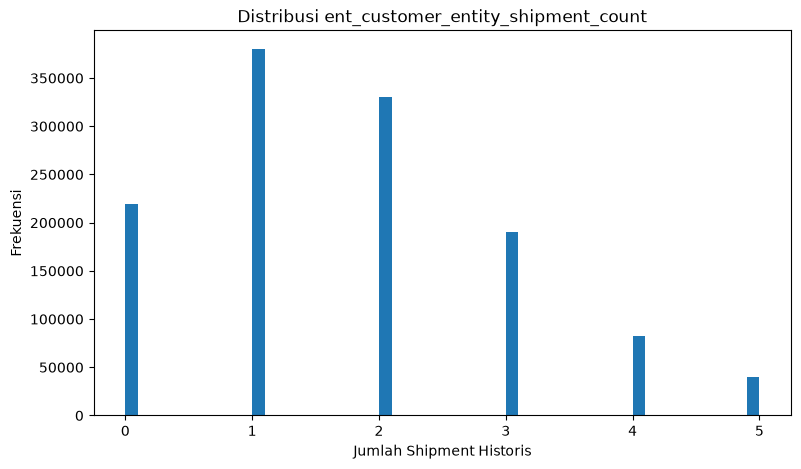

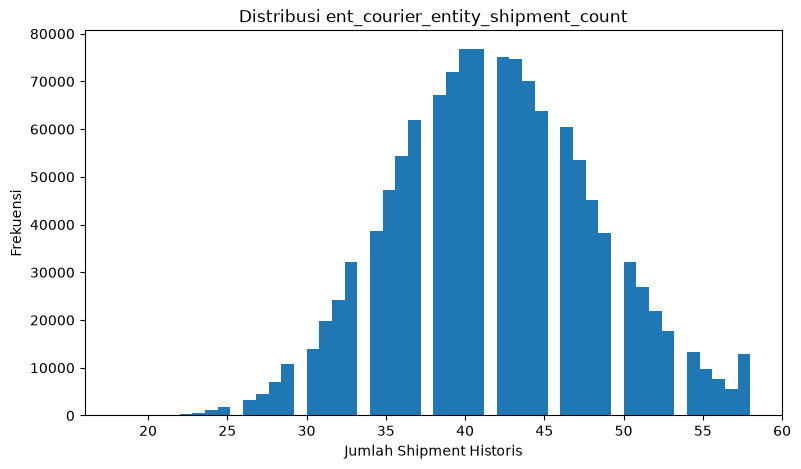

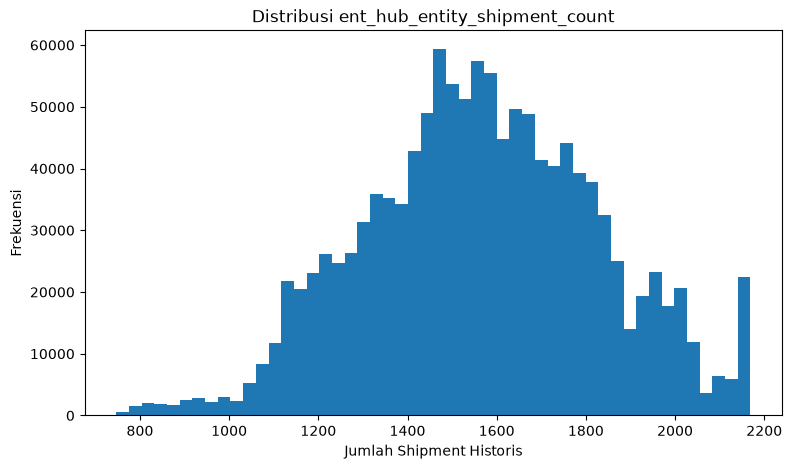

In [19]:
count_features = [
    col for col in entity_train_features.columns
    if col.endswith("_entity_shipment_count")
]

for feature in count_features:
    plt.figure(figsize=(9, 5))
    plt.hist(
        entity_train_features[feature].clip(
            upper=entity_train_features[feature].quantile(0.99)
        ),
        bins=50
    )
    plt.title(f"Distribusi {feature}")
    plt.xlabel("Jumlah Shipment Historis")
    plt.ylabel("Frekuensi")
    plt.show()
    plt.close()

In [20]:
target_encoding_results = []

for class_name in target_classes:
    class_slug = re.sub(
        r"[^a-zA-Z0-9]+",
        "_",
        str(class_name)
    ).strip("_").lower()

    target_indicator = (
        train_entity[target_column].eq(class_name).astype("int8")
    )

    class_features = [
        col for col in target_encoding_columns
        if col.endswith(f"_target_rate_{class_slug}")
    ]

    for feature in class_features:
        target_encoding_results.append({
            "class": class_name,
            "feature": feature,
            "correlation": entity_train_features[feature].corr(
                target_indicator
            )
        })

target_encoding_results = pd.DataFrame(target_encoding_results)

display(
    target_encoding_results.sort_values(
        "correlation",
        key=lambda x: x.abs(),
        ascending=False
    )
)

,class,feature,correlation
19,tertunda_operasional,ent_courier_target_rate_tertunda_operasional,0.592303
6,konfirmasi_alamat,ent_customer_target_rate_konfirmasi_alamat,0.517286
10,normal,ent_courier_target_rate_normal,0.445932
20,tertunda_operasional,ent_hub_target_rate_tertunda_operasional,0.444529
12,retur_pengirim,ent_customer_target_rate_retur_pengirim,0.373477
1,gagal_antar_awal,ent_courier_target_rate_gagal_antar_awal,0.320305
11,normal,ent_hub_target_rate_normal,0.311934
9,normal,ent_customer_target_rate_normal,0.300838
5,klaim_hilang,ent_hub_target_rate_klaim_hilang,0.249929
16,rusak_perjalanan,ent_courier_target_rate_rusak_perjalanan,0.239986


In [21]:
# Hemat RAM: tidak menggabungkan full analysis_frame (100+ kolom) di memori.
# Cukup cek skema parquet + kolom fitur entitas; penggabungan sebenarnya
# dilakukan di notebook modeling dengan membaca
# section09_outputs/entity_*_features.parquet (urutan baris sama dengan cache).

train_rows = pl.scan_parquet(train_path).select(pl.len()).collect().item()
test_rows = pl.scan_parquet(test_path).select(pl.len()).collect().item()

if train_rows != len(entity_train_features):
    raise ValueError("Jumlah baris fitur historis train tidak sama dengan analysis_frame.")

if test_rows != len(entity_test_features):
    raise ValueError("Jumlah baris fitur historis test tidak sama dengan test_analysis_frame.")

train_final_columns = list(train_columns) + list(entity_train_features.columns)
test_final_columns = list(test_columns) + list(entity_test_features.columns)

print("Train dengan fitur historis:", (train_rows, len(train_final_columns)))
print("Test dengan fitur historis:", (test_rows, len(test_final_columns)))

Train dengan fitur historis: (1243617, 230)
Test dengan fitur historis: (362245, 229)


In [22]:
train_entity_feature_names = set(entity_train_features.columns)
test_entity_feature_names = set(entity_test_features.columns)

assert train_entity_feature_names == test_entity_feature_names

assert set(train_final_columns) - {target_column} == set(test_final_columns)

print("Validasi berhasil.")
print(f"Jumlah fitur train: {len(train_final_columns) - 1:,}")
print(f"Jumlah fitur test: {len(test_final_columns):,}")

Validasi berhasil.
Jumlah fitur train: 229
Jumlah fitur test: 229


In [23]:
output_dir = Path("section09_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

entity_completeness.to_csv(
    output_dir / "entity_completeness.csv",
    index=False
)

entity_distribution.to_csv(
    output_dir / "entity_distribution.csv",
    index=False
)

entity_target_variation.to_csv(
    output_dir / "entity_target_variation.csv",
    index=False
)

entity_concentration.to_csv(
    output_dir / "entity_concentration.csv",
    index=False
)

entity_feature_summary.to_csv(
    output_dir / "entity_feature_summary.csv",
    index=False
)

target_encoding_results.to_csv(
    output_dir / "target_encoding_correlation.csv",
    index=False
)

entity_train_features.to_parquet(
    output_dir / "entity_train_features.parquet",
    index=False
)

entity_test_features.to_parquet(
    output_dir / "entity_test_features.parquet",
    index=False
)

print(f"Seluruh hasil tersimpan di: {output_dir.resolve()}")

Seluruh hasil tersimpan di: C:\Users\ASUS\.vscode\arkavidia\section09_outputs
